# Logistic Regression: Base Model

CRISP-DM phase: Modelling + Evaluation

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets (pcode as text)
train = pd.read_csv('../data/train.csv', dtype={'pcode': str})
test = pd.read_csv('../data/test.csv', dtype={'pcode': str})

In [3]:
#columns that are not features: keys, target and the baseline
not_features = ['pcode', 'county', 'year', 'month', 'flood_next_month', 'flood_this_month']

In [4]:
#separating the features (X) from the target (y)
X_train = train.drop(not_features, axis=1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis=1)
y_test = test['flood_next_month']

In [5]:
#shapes and number of floods in each set
print(X_train.shape, y_train.sum())
print(X_test.shape, y_test.sum())

(9870, 24) 882
(2820, 24) 144


#### Observation

The training set has 9,870 rows (July 2002 to December 2019) with 882 floods, and the test set has 2,820 rows (2020 to 2024) with 144 floods. Both have the 24 features. The 4 keys, the target and the baseline `flood_this_month` are not features.

## 2. Cross-Validation

All the choices below (iterations, class weights, C) are made with 5-fold cross-validation on the training set only. The test set is used once, at the end. Stratified folds keep the same share of floods (8.9%) in every fold.

The main measure is **recall for floods**: a missed flood can cost lives, while a false alarm only means a county prepares for a flood that does not come. Precision and F1 are also checked so the model does not just flag every month.

In [6]:
#stratified 5-fold cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 3. Base Model

In [7]:
#base model with all default settings
model_default = LogisticRegression()

In [8]:
#cross-validation predictions for the default model
y_pred_default = cross_val_predict(model_default, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_default, target_names=['0 no flood', '1 flood']))

c:\Users\fadhi\anaconda3\envs\flood\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\fadhi\anaconda3\envs\flood\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessi

              precision    recall  f1-score   support

  0 no flood       0.91      1.00      0.95      8988
     1 flood       0.16      0.01      0.01       882

    accuracy                           0.91      9870
   macro avg       0.53      0.50      0.48      9870
weighted avg       0.84      0.91      0.87      9870



c:\Users\fadhi\anaconda3\envs\flood\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Observation

With all default settings the model is useless for floods: it finds only 7 of the 882 floods (recall 0.01) and predicts "no flood" for almost every month. Its accuracy is 91%, but that is the same as always saying "no flood", because 91% of the months have no flood. The warnings also say that the model did not finish learning in the 100 steps it is given by default (`lbfgs failed to converge`). The next section looks at this first.

## 4. Iterations

In [9]:
#number of steps the model needed to finish learning
model_default.fit(X_train, y_train)
print(model_default.n_iter_)

[100]


c:\Users\fadhi\anaconda3\envs\flood\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Observation

The model used all 100 steps, which is the limit, so it stopped before it finished learning.

In [10]:
#giving the model 1000 steps instead of 100
model_1000 = LogisticRegression(max_iter=1000)
model_1000.fit(X_train, y_train)
print(model_1000.n_iter_)

[1000]


c:\Users\fadhi\anaconda3\envs\flood\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Observation

Even with 1,000 steps the model uses all of them and still does not finish, so more iterations are not the fix. The warning also suggests scaling the data, which the next cell looks at.

In [11]:
#the features are on very different scales
X_train[['pop_density', 'area_km2', 'rain_mm', 'lc_tree', 'month_sin']].describe().round(2)

,pop_density,area_km2,rain_mm,lc_tree,month_sin
count,9870.00,9870.00,9870.00,9870.00,9870.00
mean,509.05,12407.92,91.53,0.25,-0.02
std,1162.55,17232.55,81.99,0.19,0.71
min,6.48,234.64,0.61,0.00,-1.00
25%,51.11,2529.99,25.75,0.08,-0.87
50%,220.63,3349.54,70.80,0.21,-0.00
75%,418.64,17207.16,135.62,0.40,0.50
max,6245.84,71424.71,676.70,0.69,1.00


#### Observation

The features are on very different scales. `area_km2` goes up to 71,425 and `pop_density` up to 6,246, while `lc_tree` is between 0 and 0.69 and `month_sin` between -1 and 1. Logistic regression learns slowly when the features are this different, because one step that suits a small feature is far too small for a large one.

In [12]:
#scaling the features first, then logistic regression with default settings
model_scaled = Pipeline([('scaler', StandardScaler()),
                         ('model', LogisticRegression())])
model_scaled.fit(X_train, y_train)
print(model_scaled.named_steps['model'].n_iter_)

[17]


In [13]:
#cross-validation predictions for the scaled model
y_pred_scaled = cross_val_predict(model_scaled, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_scaled, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       0.91      0.99      0.95      8988
     1 flood       0.42      0.04      0.08       882

    accuracy                           0.91      9870
   macro avg       0.67      0.52      0.52      9870
weighted avg       0.87      0.91      0.87      9870



#### Observation

With `StandardScaler` (every feature changed to mean 0 and standard deviation 1), the model finishes learning in 17 steps, so the default 100 steps are more than enough and `max_iter` can stay at its default. The scaler is put inside a `Pipeline`, so in every fold it learns the mean and standard deviation from the training part only. Flood recall improves from 0.01 to 0.04 (39 of 882 floods found), but the model still predicts "no flood" almost every time. The cause is the class imbalance, which the next section fixes.

## 5. Class Weights

In [14]:
#share of each class in the training set
y_train.value_counts(normalize=True).round(3)

flood_next_month
0    0.911
1    0.089
Name: proportion, dtype: float64

In [15]:
#scaled model with balanced class weights
model_balanced = Pipeline([('scaler', StandardScaler()),
                           ('model', LogisticRegression(class_weight='balanced'))])
y_pred_balanced = cross_val_predict(model_balanced, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_balanced, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       0.96      0.72      0.82      8988
     1 flood       0.20      0.71      0.31       882

    accuracy                           0.72      9870
   macro avg       0.58      0.71      0.56      9870
weighted avg       0.89      0.72      0.77      9870



#### Observation

Only 8.9% of the training months are followed by a flood, so the model learns that "no flood" is almost always right. With `class_weight='balanced'` each flood counts about 10 times more than a no-flood month. Flood recall jumps from 0.04 to 0.71, so the model now finds 626 of the 882 floods instead of 39, and the misses fall from 843 to 256. The cost is more false alarms: flood precision is 0.20, so about 1 in 5 flood warnings is a real flood, and 2,555 no-flood months get a warning. Flood F1 rises from 0.08 to 0.31. Since a missed flood is the worst mistake, the class weights are kept.

## 6. Choosing C

C controls how strongly the model is held back (regularisation). A small C holds it back a lot and can cause underfitting; a large C holds it back very little and can cause overfitting. `cross_validate` gives the recall, precision and F1 of each of the 5 folds, so we can see the mean and how much it changes between folds (the standard deviation).

In [16]:
#cross-validation with C = 0.01 (strong regularisation)
model_001 = Pipeline([('scaler', StandardScaler()),
                      ('model', LogisticRegression(class_weight='balanced', C=0.01))])
scores_001 = cross_validate(model_001, X_train, y_train, cv=cv, scoring=['recall', 'precision', 'f1'])
print(scores_001['test_recall'].round(3))
print(scores_001['test_recall'].mean().round(3), scores_001['test_recall'].std().round(3))

[0.676 0.716 0.71  0.785 0.678]
0.713 0.04


In [17]:
#cross-validation with C = 0.1
model_01 = Pipeline([('scaler', StandardScaler()),
                     ('model', LogisticRegression(class_weight='balanced', C=0.1))])
scores_01 = cross_validate(model_01, X_train, y_train, cv=cv, scoring=['recall', 'precision', 'f1'])
print(scores_01['test_recall'].round(3))
print(scores_01['test_recall'].mean().round(3), scores_01['test_recall'].std().round(3))

[0.682 0.716 0.727 0.774 0.672]
0.714 0.036


In [18]:
#cross-validation with C = 1 (the default)
model_1 = Pipeline([('scaler', StandardScaler()),
                    ('model', LogisticRegression(class_weight='balanced'))])
scores_1 = cross_validate(model_1, X_train, y_train, cv=cv, scoring=['recall', 'precision', 'f1'])
print(scores_1['test_recall'].round(3))
print(scores_1['test_recall'].mean().round(3), scores_1['test_recall'].std().round(3))

[0.682 0.71  0.727 0.757 0.672]
0.71 0.031


In [19]:
#cross-validation with C = 10 (weak regularisation)
model_10 = Pipeline([('scaler', StandardScaler()),
                     ('model', LogisticRegression(class_weight='balanced', C=10))])
scores_10 = cross_validate(model_10, X_train, y_train, cv=cv, scoring=['recall', 'precision', 'f1'])
print(scores_10['test_recall'].round(3))
print(scores_10['test_recall'].mean().round(3), scores_10['test_recall'].std().round(3))

[0.682 0.71  0.727 0.757 0.672]
0.71 0.031


In [20]:
#comparing the four values of C
cv_results = pd.DataFrame({'C': [0.01, 0.1, 1, 10],
                           'mean recall': [scores_001['test_recall'].mean(), scores_01['test_recall'].mean(), scores_1['test_recall'].mean(), scores_10['test_recall'].mean()],
                           'std recall': [scores_001['test_recall'].std(), scores_01['test_recall'].std(), scores_1['test_recall'].std(), scores_10['test_recall'].std()],
                           'mean precision': [scores_001['test_precision'].mean(), scores_01['test_precision'].mean(), scores_1['test_precision'].mean(), scores_10['test_precision'].mean()],
                           'mean f1': [scores_001['test_f1'].mean(), scores_01['test_f1'].mean(), scores_1['test_f1'].mean(), scores_10['test_f1'].mean()]})
cv_results.round(3)

,C,mean recall,std recall,mean precision,mean f1
0,0.01,0.713,0.040,0.197,0.309
1,0.10,0.714,0.036,0.198,0.310
2,1.00,0.710,0.031,0.197,0.308
3,10.00,0.710,0.031,0.197,0.308


#### Observation

The four values of C give almost the same mean recall (0.713, 0.714, 0.710 and 0.710), precision (0.197 to 0.198) and F1 (0.308 to 0.310). The biggest difference in mean recall (0.004) is much smaller than the normal change between folds (a standard deviation of 0.031 to 0.040), so the amount of regularisation makes no real difference to this model. C = 1 and C = 10 give the same results, and C = 1 has the smallest standard deviation (0.031), so we keep C = 1, the default. Its fold recalls go from 0.672 to 0.757, so the result is stable across folds.

### 6.1 A Stricter Check: Whole Years Held Out

The stratified folds mix months from all years, so a fold can train on April 2015 in one county and be tested on April 2015 in a neighbouring county. Rain, ONI and DMI are very similar for those two rows, which can make the scores look better and more stable than they really are. As a check, `GroupKFold` with `groups=train['year']` keeps whole years together, so each fold is tested on years the model has not seen at all.

In [21]:
#5 folds that keep whole years together, for the chosen model
year_cv = GroupKFold(n_splits=5)
scores_years = cross_validate(model_1, X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_years['test_recall'].round(3))
print(scores_years['test_recall'].mean().round(3), scores_years['test_recall'].std().round(3))
print(scores_years['test_precision'].mean().round(3), scores_years['test_f1'].mean().round(3))

[0.57  0.646 0.536 0.77  0.624]
0.629 0.08
0.194 0.291


#### Observation

When whole years are held out, the recall drops from 0.710 to 0.629, and it changes much more between folds (from 0.536 to 0.770, standard deviation 0.080 against 0.031). Precision (0.194) and F1 (0.291) are close to the stratified folds. So the stratified scores are a little too optimistic about recall, and the year-based folds give a more honest idea of what to expect on new years. For the Random Forest and XGBoost notebooks, the year-based folds are the safer choice for tuning.

## 7. Evaluation on the Test Set

### 7.1 Fitting the Final Base Model

The tests above give the final settings: the features are scaled with `StandardScaler`, the default 100 iterations are enough once the features are scaled, `class_weight='balanced'`, and the default `C = 1`. The model is fitted on the whole training set and scored once on the test set (2020 to 2024).

In [22]:
#fitting on the full training set and predicting the test set
model = Pipeline([('scaler', StandardScaler()),
                  ('model', LogisticRegression(class_weight='balanced'))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

### 7.2 Classification Report

In [23]:
#recall, precision and f1 for each class on the test set
print(classification_report(y_test, y_pred, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       0.98      0.66      0.79      2676
     1 flood       0.11      0.81      0.20       144

    accuracy                           0.67      2820
   macro avg       0.55      0.73      0.49      2820
weighted avg       0.94      0.67      0.76      2820



In [24]:
#flood recall on the test set, to compare with the cross-validation score
print(round(recall_score(y_test, y_pred), 3))

0.806


#### Observation

On the test set the model finds 80.6% of the floods (recall 0.806), which is higher than both cross-validation scores (0.710 stratified and 0.629 by year). The difference is partly luck, because the test set has only 144 floods, so each flood found or missed moves the recall by 0.7 percentage points. Flood precision is 0.11, so about 1 in 9 flood warnings is a real flood, and flood F1 is 0.20. Precision is lower than in cross-validation (0.20) partly because floods are rarer in the test years (5.1% against 8.9%). Accuracy is 67%, but as shown in Section 3, accuracy does not tell us how many floods are found.

### 7.3 Confusion Matrix

Each row is the true outcome and each column is the prediction, so the numbers on the diagonal are correct predictions.

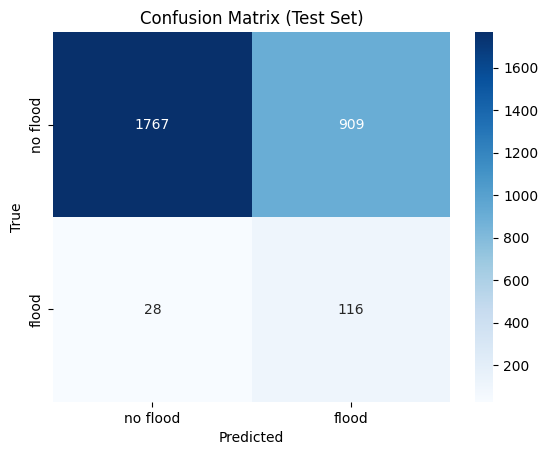

In [25]:
#confusion matrix of the test set
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.show()

#### Observation

Of the 144 months followed by a flood, the model finds 116 and misses 28. Of the 2,676 months with no flood, 1,767 are correct and 909 get a false alarm. The model raises 1,025 warnings in total, so for every flood it finds there are about 8 false alarms.

## 8. Comparison with the Persistence Baseline

The persistence baseline predicts a flood next month whenever there is a flood this month (`flood_this_month`). It needs no model, so the model is only useful if it does better.

In [26]:
#baseline predictions on the test set
base_pred = test['flood_this_month']

In [27]:
#recall, precision, f1 and roc-auc for the baseline and the model
comparison = pd.DataFrame({'method': ['Persistence baseline', 'Logistic regression'],
                           'recall': [recall_score(y_test, base_pred), recall_score(y_test, y_pred)],
                           'precision': [precision_score(y_test, base_pred), precision_score(y_test, y_pred)],
                           'f1': [f1_score(y_test, base_pred), f1_score(y_test, y_pred)],
                           'roc-auc': [roc_auc_score(y_test, base_pred), roc_auc_score(y_test, y_prob)]})
comparison.round(3)

,method,recall,precision,f1,roc-auc
0,Persistence baseline,0.472,0.472,0.472,0.722
1,Logistic regression,0.806,0.113,0.198,0.807


#### Observation

The model beats the baseline on the main measure, recall: it finds 116 of the 144 floods (0.806) against 68 for the baseline (0.472), so it misses 28 floods instead of 76. It also ranks months better (ROC-AUC 0.807 against 0.722). The baseline is much more precise (0.472 against 0.113): it raises only 76 false alarms against 909 for the model, so its F1 is also higher (0.472 against 0.198). The model therefore does what we want most, which is to catch more floods, but it does so with many more false alarms. The model uses a cut of 0.5 on the flood probability; a different cut could trade some recall for fewer false alarms, but that cut would have to be chosen in cross-validation and not on the test set.

## 9. Summary of the Base Model

- **Base model:** `StandardScaler` followed by logistic regression with `class_weight='balanced'`, `C = 1` and the default 100 iterations, trained on the 24 features (July 2002 to December 2019) to predict whether a county floods next month.
- **What each step did:** the default model found only 7 of 882 floods in cross-validation and did not finish learning. More iterations did not help; scaling the features did (17 steps). Balanced class weights raised cross-validation recall from 0.04 to 0.71. The value of C made no real difference.
- **Validity:** stratified 5-fold cross-validation gave a recall of 0.710 (standard deviation 0.031). Holding out whole years gave 0.629 (standard deviation 0.080), which is the more honest estimate.
- **Test set (2020 to 2024):** recall 0.806, precision 0.113, F1 0.198 and ROC-AUC 0.807. The model finds 116 of the 144 floods, misses 28 and raises 909 false alarms.
- **Against the persistence baseline:** much better recall (0.806 against 0.472) and ROC-AUC (0.807 against 0.722), but much lower precision (0.113 against 0.472) and F1 (0.198 against 0.472).
- **Limits:** the test set has only 144 floods, the probability cut is fixed at 0.5, and `county_flood_rate` is calculated from all training years, so it is slightly optimistic inside cross-validation.

The next notebook, `RandomForest_Base.ipynb`, will be compared with this model on the same files and with the same measures.